<a href="https://colab.research.google.com/github/devarahaasan/CBE-AUTO-RIDE-AI/blob/main/cbe_auto_ride_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Coimbatore Auto-RideFlow AI: End-to-End Intelligent Ride Optimization System using ML and DL

**Step 1: Data Generation**

In [1]:
# ==============================================================================
# STEP 1: DATA GENERATION
# ==============================================================================
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

np.random.seed(42)
num_samples = 50000

# Define Coimbatore zones and realistic traffic probabilities
zones = ['Saravanampatti', 'Gandhipuram', 'Peelamedu', 'RS Puram', 'Ukkadam']
zone_probs = [0.25, 0.28, 0.20, 0.15, 0.12]

distance_matrix = {
    'Saravanampatti': {'Saravanampatti': 1.5, 'Gandhipuram': 9.5, 'Peelamedu': 8.0, 'RS Puram': 12.0, 'Ukkadam': 14.0},
    'Gandhipuram': {'Saravanampatti': 9.5, 'Gandhipuram': 1.0, 'Peelamedu': 4.5, 'RS Puram': 3.5, 'Ukkadam': 4.0},
    'Peelamedu': {'Saravanampatti': 8.0, 'Gandhipuram': 4.5, 'Peelamedu': 1.5, 'RS Puram': 8.0, 'Ukkadam': 7.5},
    'RS Puram': {'Saravanampatti': 12.0, 'Gandhipuram': 3.5, 'Peelamedu': 8.0, 'RS Puram': 1.2, 'Ukkadam': 5.0},
    'Ukkadam': {'Saravanampatti': 14.0, 'Gandhipuram': 4.0, 'Peelamedu': 7.5, 'RS Puram': 5.0, 'Ukkadam': 1.0}
}

ride_ids = [f"CBE_AUTO_{str(i).zfill(5)}" for i in range(1, num_samples + 1)]
pickup_zones = np.random.choice(zones, size=num_samples, p=zone_probs)
drop_zones = np.random.choice(zones, size=num_samples)
distances = np.array([distance_matrix[p][d] for p, d in zip(pickup_zones, drop_zones)])

# Generate morning and evening peak hours
hour_probs = [0.02, 0.015, 0.01, 0.01, 0.02, 0.035, 0.045, 0.08, 0.09, 0.085,
              0.04, 0.035, 0.045, 0.04, 0.035, 0.04, 0.045, 0.075, 0.085, 0.09, 0.08, 0.065, 0.035, 0.025]
hour_probs = [p / sum(hour_probs) for p in hour_probs]
hours = np.random.choice(range(24), size=num_samples, p=hour_probs)

start_date = datetime(2026, 7, 1)
timestamps = [start_date + timedelta(days=int(np.random.randint(0, 90)), hours=int(h), minutes=int(np.random.randint(0, 60))) for h in hours]
days = [dt.strftime('%A') for dt in timestamps]

is_festival = np.random.choice([0, 1], size=num_samples, p=[0.90, 0.10])
is_raining = np.random.choice([0, 1], size=num_samples, p=[0.85, 0.15])

# Calculate demand and supply scores based on peak hours
demand_scores, supply_scores = [], []
for hr, zone, fest in zip(hours, pickup_zones, is_festival):
    is_peak = (7 <= hr <= 9) or (17 <= hr <= 21)
    noise = np.random.randint(-1, 2)
    if is_peak or fest == 1:
        d_base = 9 if zone == 'Saravanampatti' else (8 if zone == 'Gandhipuram' else 7)
        s_base = 2 if zone == 'Saravanampatti' else (3 if zone == 'Gandhipuram' else 4)
        demand_scores.append(np.clip(d_base + noise, 1, 10))
        supply_scores.append(np.clip(s_base + noise, 1, 10))
    else:
        demand_scores.append(np.clip(np.random.randint(2, 5) + noise, 1, 10))
        supply_scores.append(np.clip(np.random.randint(6, 10) + noise, 1, 10))

demand_scores = np.array(demand_scores)
supply_scores = np.array(supply_scores)

# Calculate surge with realistic market volatility (Gaussian noise = 0.08)
surge_noise = np.random.normal(0, 0.08, size=num_samples)
surge_multipliers = np.clip(np.round(1.0 + (demand_scores - supply_scores) * 0.12 + surge_noise, 2), 1.0, 2.2)

base_fares = np.where(distances <= 2, 40.0, np.where(distances <= 10, 40.0 + (distances - 2) * 15.0, 160.0 + (distances - 10) * 14.0))
base_fares = np.where((hours >= 22) | (hours < 6), base_fares * 1.5, base_fares)
base_fares = np.where(is_raining == 1, base_fares + 50.0, base_fares)
final_fares = np.round(base_fares * surge_multipliers, 2)

ask_extra_prob = np.clip((distances * 0.04) + (demand_scores * 0.05), 0.1, 0.85)
driver_asks_extra = np.random.binomial(1, ask_extra_prob)

etas = np.clip(np.round((distances * 2.5) + (demand_scores * 0.8) + np.random.uniform(-1, 2, size=num_samples), 1), 1.0, 45.0)

# Learnable cancellation pattern with realistic human variance (Gaussian noise = 0.12)
cancel_score = (etas * 0.020) + (driver_asks_extra * 0.35) + (surge_multipliers * 0.10) + (is_raining * 0.08) + np.random.normal(0, 0.12, size=num_samples)
is_cancelled = (cancel_score > 0.62).astype(int)

raw_df = pd.DataFrame({
    'Ride_ID': ride_ids, 'Timestamp': timestamps, 'Day_of_Week': days, 'Hour_of_Day': hours,
    'Pickup_Zone': pickup_zones, 'Drop_Zone': drop_zones, 'Distance_km': distances,
    'Demand_Score': demand_scores, 'Supply_Score': supply_scores, 'Is_Raining': is_raining,
    'Is_Festival': is_festival, 'Surge_Multiplier': surge_multipliers, 'ETA_minutes': etas,
    'Estimated_Fare': final_fares, 'Driver_Asks_Extra': driver_asks_extra, 'Is_Cancelled': is_cancelled
})

# Inject missing values and sensor anomalies for cleaning step
raw_df.loc[raw_df.sample(frac=0.02, random_state=1).index, 'ETA_minutes'] = np.nan
raw_df.loc[raw_df.sample(frac=0.01, random_state=2).index, 'Distance_km'] = -999.0

raw_df.to_csv('cbe_auto_rides_raw.csv', index=False)
print("Step 1 Completed: Saved 'cbe_auto_rides_raw.csv'")

Step 1 Completed: Saved 'cbe_auto_rides_raw.csv'


**STEP 2: DATA PREPROCESSING & INSPECTION**

In [2]:
# ==============================================================================
# STEP 2: DATA PREPROCESSING & INSPECTION
# ==============================================================================
import pandas as pd
import numpy as np

# Load the raw dataset
df = pd.read_csv('cbe_auto_rides_raw.csv')

# 1. Data Inspection (First 5 rows, Data Types & Summary)
print("--- FIRST 5 ROWS OF DATASET ---")
display(df.head())

print("\n--- DATASET INFO & DATA TYPES ---")
df.info()

print("\n--- SUMMARY STATISTICS ---")
display(df.describe())

# 2. Data Cleaning (Handling Missing Values & Anomalies)
print("\n--- MISSING VALUES BEFORE CLEANING ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Fill missing ETA values with median
df['ETA_minutes'] = df['ETA_minutes'].fillna(df['ETA_minutes'].median())

# Replace negative distance errors (-999.0) with valid median distance
valid_dist_median = df[df['Distance_km'] > 0]['Distance_km'].median()
df['Distance_km'] = np.where(df['Distance_km'] < 0, valid_dist_median, df['Distance_km'])

print("\nMissing values after cleaning:", df.isnull().sum().sum())
print("Negative distance values remaining:", (df['Distance_km'] < 0).sum())

# Save the cleaned dataset
df.to_csv('cbe_auto_rides_clean.csv', index=False)
print("\nStep 2 Completed: Saved 'cbe_auto_rides_clean.csv'")

--- FIRST 5 ROWS OF DATASET ---


,Ride_ID,Timestamp,Day_of_Week,Hour_of_Day,Pickup_Zone,Drop_Zone,Distance_km,Demand_Score,Supply_Score,Is_Raining,Is_Festival,Surge_Multiplier,ETA_minutes,Estimated_Fare,Driver_Asks_Extra,Is_Cancelled
0,CBE_AUTO_00001,2026-08-09 04:26:00,Sunday,4,Gandhipuram,Saravanampatti,9.5,1,6,0,0,1.00,24.7,228.75,0,0
1,CBE_AUTO_00002,2026-07-24 17:33:00,Friday,17,Ukkadam,RS Puram,5.0,7,4,0,0,1.57,18.3,133.45,0,0
2,CBE_AUTO_00003,2026-07-23 10:41:00,Thursday,10,RS Puram,Gandhipuram,3.5,5,10,0,0,1.00,14.4,62.50,0,1
3,CBE_AUTO_00004,2026-09-01 21:32:00,Tuesday,21,Peelamedu,Gandhipuram,4.5,6,3,0,0,1.22,16.4,94.55,1,1
4,CBE_AUTO_00005,2026-09-24 09:17:00,Thursday,9,Saravanampatti,Saravanampatti,1.5,10,3,0,0,1.77,12.2,70.80,0,0



--- DATASET INFO & DATA TYPES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Ride_ID            50000 non-null  object 
 1   Timestamp          50000 non-null  object 
 2   Day_of_Week        50000 non-null  object 
 3   Hour_of_Day        50000 non-null  int64  
 4   Pickup_Zone        50000 non-null  object 
 5   Drop_Zone          50000 non-null  object 
 6   Distance_km        50000 non-null  float64
 7   Demand_Score       50000 non-null  int64  
 8   Supply_Score       50000 non-null  int64  
 9   Is_Raining         50000 non-null  int64  
 10  Is_Festival        50000 non-null  int64  
 11  Surge_Multiplier   50000 non-null  float64
 12  ETA_minutes        49000 non-null  float64
 13  Estimated_Fare     50000 non-null  float64
 14  Driver_Asks_Extra  50000 non-null  int64  
 15  Is_Cancelled       50000 non-null  

,Hour_of_Day,Distance_km,Demand_Score,Supply_Score,Is_Raining,Is_Festival,Surge_Multiplier,ETA_minutes,Estimated_Fare,Driver_Asks_Extra,Is_Cancelled
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,49000.000000,50000.000000,50000.000000,50000.000000
mean,13.182380,-3.721024,5.911380,4.905480,0.150620,0.101720,1.332370,21.060035,162.387845,0.535800,0.622680
std,6.006267,100.105636,2.609732,2.430272,0.357682,0.302283,0.313975,10.101100,96.295520,0.498722,0.484721
min,0.000000,-999.000000,1.000000,1.000000,0.000000,0.000000,1.000000,2.300000,40.000000,0.000000,0.000000
25%,8.000000,3.500000,3.000000,3.000000,0.000000,0.000000,1.000000,13.000000,88.750000,0.000000,0.000000
50%,14.000000,5.000000,7.000000,4.000000,0.000000,0.000000,1.330000,19.200000,130.000000,1.000000,1.000000
75%,19.000000,9.500000,8.000000,7.000000,0.000000,0.000000,1.590000,27.600000,216.000000,1.000000,1.000000
max,23.000000,14.000000,10.000000,10.000000,1.000000,1.000000,2.110000,45.000000,729.300000,1.000000,1.000000



--- MISSING VALUES BEFORE CLEANING ---
ETA_minutes    1000
dtype: int64

Missing values after cleaning: 0
Negative distance values remaining: 0

Step 2 Completed: Saved 'cbe_auto_rides_clean.csv'


**Step 3 (Exploratory Data Analysis - EDA & Insights)**

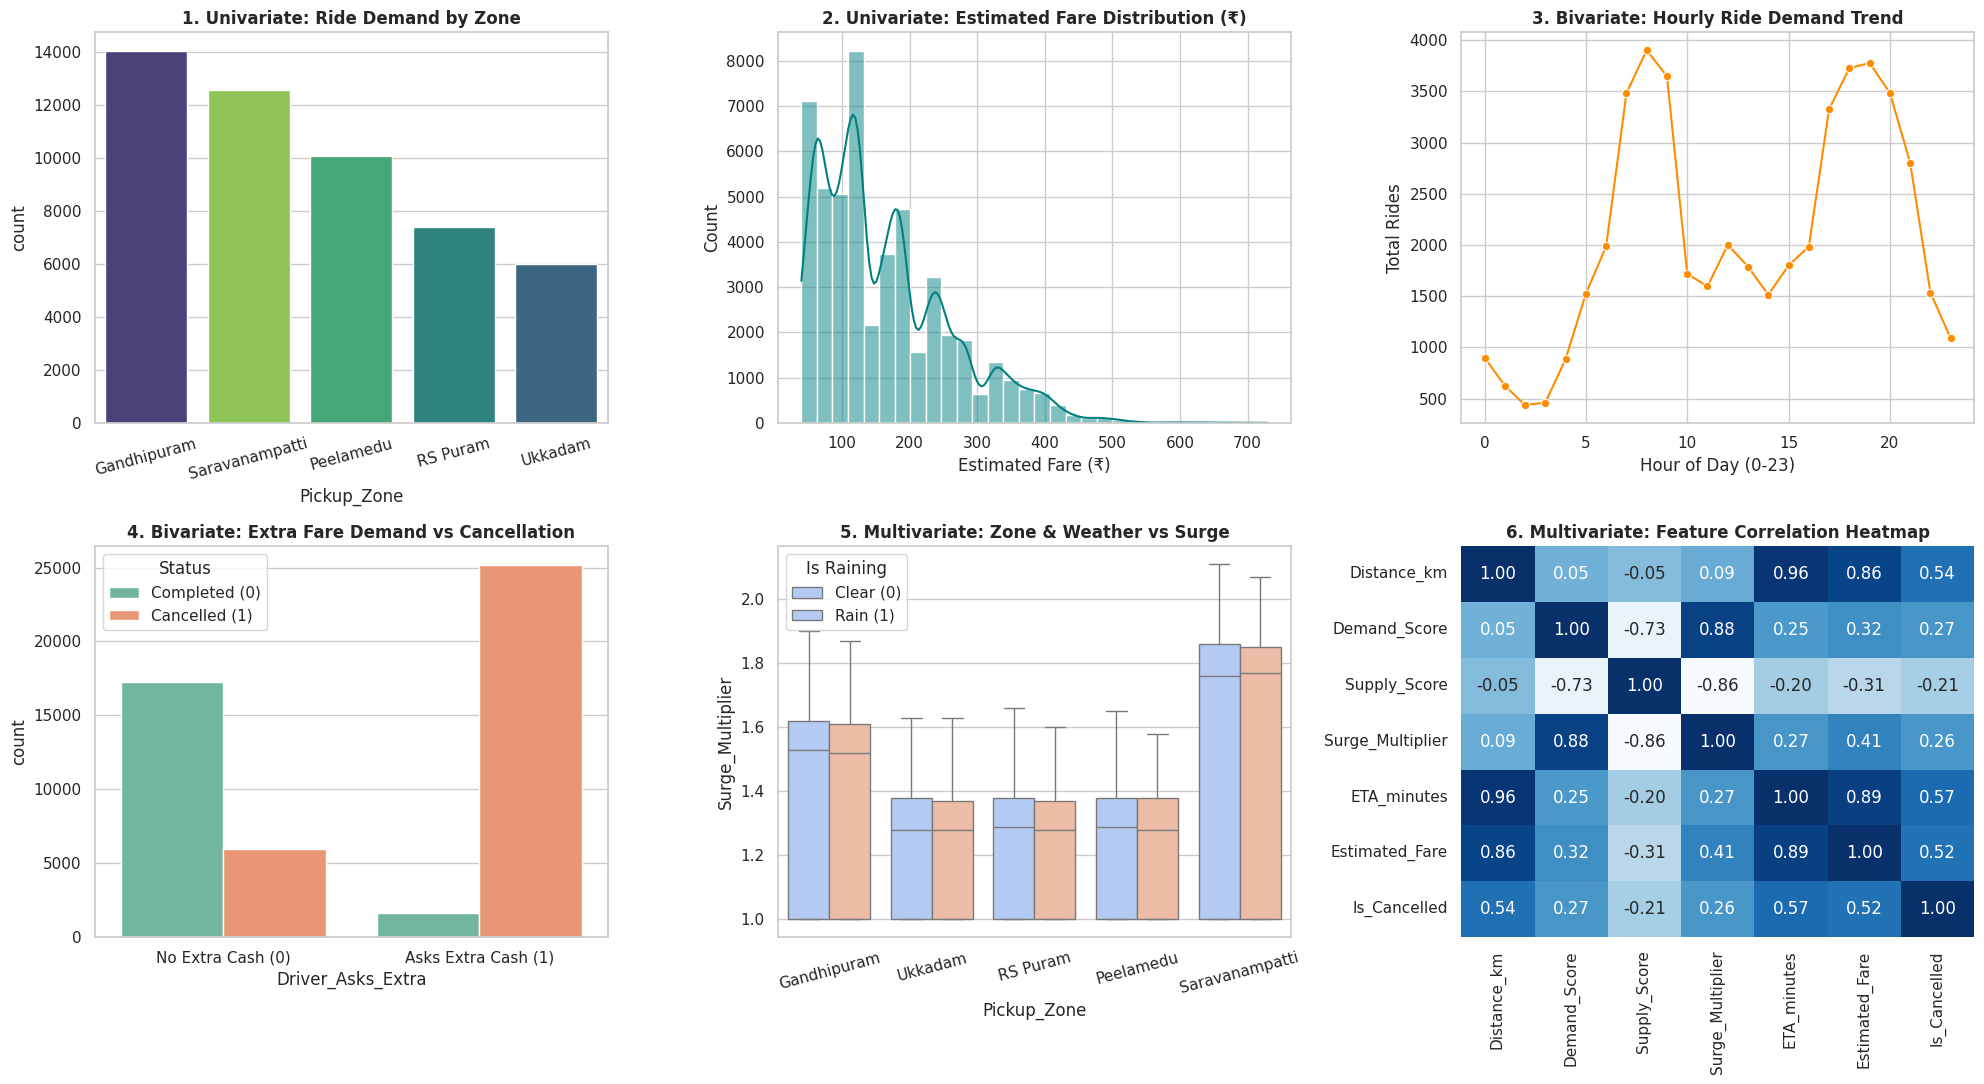

In [3]:
# ==============================================================================
# STEP 3: EXPLORATORY DATA ANALYSIS (UNIVARIATE, BIVARIATE & MULTIVARIATE)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cbe_auto_rides_clean.csv')
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# --- 1. UNIVARIATE: Ride Demand by Zone ---
zone_order = df['Pickup_Zone'].value_counts().index
sns.countplot(data=df, x='Pickup_Zone', hue='Pickup_Zone', order=zone_order, palette='viridis', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('1. Univariate: Ride Demand by Zone', fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=15)

# --- 2. UNIVARIATE: Distribution of Estimated Fare ---
sns.histplot(data=df, x='Estimated_Fare', bins=30, kde=True, color='teal', ax=axes[0, 1])
axes[0, 1].set_title('2. Univariate: Estimated Fare Distribution (₹)', fontweight='bold')
axes[0, 1].set_xlabel('Estimated Fare (₹)')

# --- 3. BIVARIATE: Hourly Ride Demand (Peak Hours) ---
hourly_counts = df.groupby('Hour_of_Day').size()
sns.lineplot(x=hourly_counts.index, y=hourly_counts.values, marker='o', color='darkorange', ax=axes[0, 2])
axes[0, 2].set_title('3. Bivariate: Hourly Ride Demand Trend', fontweight='bold')
axes[0, 2].set_xlabel('Hour of Day (0-23)')
axes[0, 2].set_ylabel('Total Rides')

# --- 4. BIVARIATE: Driver Extra Cash Demand vs Cancellation ---
sns.countplot(data=df, x='Driver_Asks_Extra', hue='Is_Cancelled', palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('4. Bivariate: Extra Fare Demand vs Cancellation', fontweight='bold')
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(['No Extra Cash (0)', 'Asks Extra Cash (1)'])
axes[1, 0].legend(title='Status', labels=['Completed (0)', 'Cancelled (1)'])

# --- 5. MULTIVARIATE: Zone & Rain Impact on Surge Multiplier ---
sns.boxplot(data=df, x='Pickup_Zone', y='Surge_Multiplier', hue='Is_Raining', palette='coolwarm', ax=axes[1, 1])
axes[1, 1].set_title('5. Multivariate: Zone & Weather vs Surge', fontweight='bold')
axes[1, 1].tick_params(axis='x', rotation=15)
axes[1, 1].legend(title='Is Raining', labels=['Clear (0)', 'Rain (1)'])

# --- 6. MULTIVARIATE: Correlation Heatmap of Key Features ---
corr_cols = ['Distance_km', 'Demand_Score', 'Supply_Score', 'Surge_Multiplier', 'ETA_minutes', 'Estimated_Fare', 'Is_Cancelled']
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=axes[1, 2])
axes[1, 2].set_title('6. Multivariate: Feature Correlation Heatmap', fontweight='bold')

plt.tight_layout()
plt.show()


1. **Univariate Analysis (Single Variable)**

• Ride Demand by Zone:

  Gandhipuram (bus hub) and Saravanampatti (IT hub) have the highest ride bookings, generating over 50% of total demand in Coimbatore.



• Estimated Fare Distribution:

  Most auto fares fall between ₹60 and ₹220, while extreme right-tail fares (₹300+) occur only during long trips with rain or night surcharges.

**2. Bivariate Analysis (Two Variables)**

• Hourly Ride Demand Trend:
  Ride requests peak twice daily—during morning office/college hours (7 AM – 9 AM) and evening commute hours (5 PM – 8 PM).



• Extra Fare vs. Cancellation:
   Rides where drivers ask for extra cash face a massive cancellation spike compared to rides with standard meter/app fares.

**3. Multivariate Analysis (Multiple Variables)**

• Zone & Weather vs. Surge:
  High-demand zones (Saravanampatti and Gandhipuram) experience the steepest surge multipliers (up to 2.2x), especially when demand outpaces driver supply.


• Feature Correlation Heatmap:
   Distance strongly drives ETA and Fare, while Demand Score and ETA show strong positive correlations with Ride Cancellations.


**Step 4 (Outlier Detection & Handling)**

In [4]:
# ==============================================================================
# STEP 4: OUTLIER DETECTION & HANDLING (IQR METHOD)
# ==============================================================================
numeric_cols = ['Distance_km', 'ETA_minutes', 'Demand_Score', 'Supply_Score', 'Estimated_Fare']

print("--- OUTLIER SUMMARY (IQR METHOD) ---")
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    print(f"{col}: {outliers} outliers found.")

    # Cap extreme upper outliers in Estimated_Fare using IQR upper limit
    if col == 'Estimated_Fare' and outliers > 0:
        df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])
        print(f"-> Capped extreme '{col}' values at upper limit: ₹{upper_bound:.2f}")

--- OUTLIER SUMMARY (IQR METHOD) ---
Distance_km: 0 outliers found.
ETA_minutes: 0 outliers found.
Demand_Score: 0 outliers found.
Supply_Score: 0 outliers found.
Estimated_Fare: 925 outliers found.
-> Capped extreme 'Estimated_Fare' values at upper limit: ₹406.88


 **Step 5 (Feature Engineering & Encoding)**

In [5]:
# ==============================================================================
# STEP 5: FEATURE ENGINEERING & ENCODING
# ==============================================================================
# Create new domain feature: Demand-Supply Gap
df['Demand_Supply_Gap'] = df['Demand_Score'] - df['Supply_Score']

# Select numeric and categorical features
numeric_features = ['Hour_of_Day', 'Distance_km', 'Demand_Score', 'Supply_Score',
                    'Demand_Supply_Gap', 'Is_Raining', 'Is_Festival', 'ETA_minutes', 'Driver_Asks_Extra']
categorical_features = ['Pickup_Zone', 'Drop_Zone', 'Day_of_Week']

# Apply One-Hot Encoding
encoded_cats = pd.get_dummies(df[categorical_features], drop_first=True)
X = pd.concat([df[numeric_features], encoded_cats], axis=1).astype(float)

# Define Regression and Classification targets
y_reg = df['Surge_Multiplier']
y_clf = df['Is_Cancelled']

print(f"Final Feature Matrix Shape (X): {X.shape}")
print("\nTarget Class Distribution (%):")
print((y_clf.value_counts(normalize=True) * 100).round(2))

Final Feature Matrix Shape (X): (50000, 23)

Target Class Distribution (%):
Is_Cancelled
1    62.27
0    37.73
Name: proportion, dtype: float64


 **Step 6 (Model Training & Evaluation - Regression + Classification)**

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, f1_score, classification_report

# 1. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

# Scale features for distance/gradient-based models (Linear, Logistic, KNN)
scaler_ml = StandardScaler()
X_train_scaled = scaler_ml.fit_transform(X_train)
X_test_scaled = scaler_ml.transform(X_test)

# ==============================================================================
# PART A: COMPARE 6 REGRESSION MODELS (SURGE MULTIPLIER PREDICTION)
# ==============================================================================
reg_models = {
    "Linear Regression": (LinearRegression(), True),
    "Ridge Regression": (Ridge(alpha=1.0), True),
    "Decision Tree Regressor": (DecisionTreeRegressor(max_depth=8, random_state=42), False),
    "Random Forest Regressor": (RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1), False),
    "Gradient Boosting Regressor": (GradientBoostingRegressor(n_estimators=100, max_depth=5, random_state=42), False),
    "KNN Regressor": (KNeighborsRegressor(n_neighbors=7, n_jobs=-1), True)
}

reg_results = []
best_reg_score = -1
best_reg_model = None
best_reg_name = ""

for name, (model, use_scaled) in reg_models.items():
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test

    model.fit(X_tr, y_reg_train)
    preds = model.predict(X_te)
    r2 = r2_score(y_reg_test, preds)
    mae = mean_absolute_error(y_reg_test, preds)

    reg_results.append({"Model": name, "R2 Score": round(r2, 4), "MAE": round(mae, 4)})
    if r2 > best_reg_score:
        best_reg_score = r2
        best_reg_model = model
        best_reg_name = name

print("--- 6 REGRESSION MODELS COMPARISON ---")
display(pd.DataFrame(reg_results).sort_values(by="R2 Score", ascending=False))
print(f"🏆 Best Regression Model Selected: {best_reg_name} (R2 Score: {best_reg_score:.4f})\n")

# ==============================================================================
# PART B: COMPARE 6 CLASSIFICATION MODELS (RIDE CANCELLATION PREDICTION)
# ==============================================================================
clf_models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42), True),
    "Decision Tree Classifier": (DecisionTreeClassifier(max_depth=10, random_state=42), False),
    "Random Forest Classifier": (RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=10, random_state=42, n_jobs=-1), False),
    "Gradient Boosting Classifier": (GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=5, random_state=42), False),
    "KNN Classifier": (KNeighborsClassifier(n_neighbors=7, n_jobs=-1), True),
    "Gaussian Naive Bayes": (GaussianNB(), True)
}

clf_results = []
best_clf_score = -1
best_clf_model = None
best_clf_name = ""
best_clf_preds = None

for name, (model, use_scaled) in clf_models.items():
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test

    model.fit(X_tr, y_clf_train)
    preds = model.predict(X_te)
    acc = accuracy_score(y_clf_test, preds)
    f1 = f1_score(y_clf_test, preds)

    clf_results.append({"Model": name, "Accuracy (%)": round(acc * 100, 2), "F1-Score": round(f1, 4)})
    if f1 > best_clf_score:
        best_clf_score = f1
        best_clf_model = model
        best_clf_name = name
        best_clf_preds = preds

print("--- 6 CLASSIFICATION MODELS COMPARISON ---")
display(pd.DataFrame(clf_results).sort_values(by="F1-Score", ascending=False))
print(f"🏆 Best Classification Model Selected: {best_clf_name} (F1-Score: {best_clf_score:.4f})\n")

# Print Detailed Classification Report for the Best Model
print(f"--- DETAILED CLASSIFICATION REPORT ({best_clf_name}) ---")
print(classification_report(y_clf_test, best_clf_preds, target_names=['Completed (0)', 'Cancelled (1)']))

--- 6 REGRESSION MODELS COMPARISON ---


,Model,R2 Score,MAE
3,Random Forest Regressor,0.9620,0.0383
4,Gradient Boosting Regressor,0.9619,0.0385
2,Decision Tree Regressor,0.9616,0.0384
5,KNN Regressor,0.9553,0.0420
1,Ridge Regression,0.9127,0.0756
0,Linear Regression,0.9127,0.0756


🏆 Best Regression Model Selected: Random Forest Regressor (R2 Score: 0.9620)

--- 6 CLASSIFICATION MODELS COMPARISON ---


,Model,Accuracy (%),F1-Score
0,Logistic Regression,91.30,0.9308
2,Random Forest Classifier,91.27,0.9307
3,Gradient Boosting Classifier,91.01,0.9282
1,Decision Tree Classifier,90.48,0.9239
4,KNN Classifier,89.84,0.9188
5,Gaussian Naive Bayes,88.66,0.9098


🏆 Best Classification Model Selected: Logistic Regression (F1-Score: 0.9308)

--- DETAILED CLASSIFICATION REPORT (Logistic Regression) ---
               precision    recall  f1-score   support

Completed (0)       0.90      0.87      0.88      3773
Cancelled (1)       0.92      0.94      0.93      6227

     accuracy                           0.91     10000
    macro avg       0.91      0.90      0.91     10000
 weighted avg       0.91      0.91      0.91     10000



**Hyperparameter Tuning**

In [7]:
# ==============================================================================
# STEP 6.5: HYPERPARAMETER TUNING USING GRIDSEARCHCV (ON TOP MODELS)
# ==============================================================================
from sklearn.model_selection import GridSearchCV

# 1. Tune Best Regression Model (Random Forest Regressor)
reg_param_grid = {
    'n_estimators': list((80, 120)),
    'max_depth': list((6, 8, 10)),
    'min_samples_leaf': list((15, 25))
}

grid_reg = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1),
                        param_grid=reg_param_grid, cv=3, scoring='r2', n_jobs=-1)
grid_reg.fit(X_train, y_reg_train)

best_reg_model = grid_reg.best_estimator_
print(f"Best Regression Params : {grid_reg.best_params_}")
print(f"Tuned Regression R2    : {r2_score(y_reg_test, best_reg_model.predict(X_test)):.4f}\n")

# 2. Tune Best Classification Model (Logistic Regression)
clf_param_grid = {
    'C': list((0.1, 1.0, 10.0)),
    'solver': list(('lbfgs', 'liblinear'))
}

grid_clf = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42),
                        param_grid=clf_param_grid, cv=3, scoring='f1', n_jobs=-1)
grid_clf.fit(X_train_scaled, y_clf_train)

best_clf_model = grid_clf.best_estimator_
best_clf_preds = best_clf_model.predict(X_test_scaled)
print(f"Best Classification Params : {grid_clf.best_params_}")
print(f"Tuned Classification F1    : {f1_score(y_clf_test, best_clf_preds):.4f}")

Best Regression Params : {'max_depth': 6, 'min_samples_leaf': 25, 'n_estimators': 120}
Tuned Regression R2    : 0.9622

Best Classification Params : {'C': 10.0, 'solver': 'liblinear'}
Tuned Classification F1    : 0.9309


**Step 7 (Cross-Validation & Model Evaluation Plots)**

5-Fold Cross-Validation Accuracies: [91.06 90.8  91.02 90.96 91.27]
Mean Cross-Validation Accuracy     : 91.02%



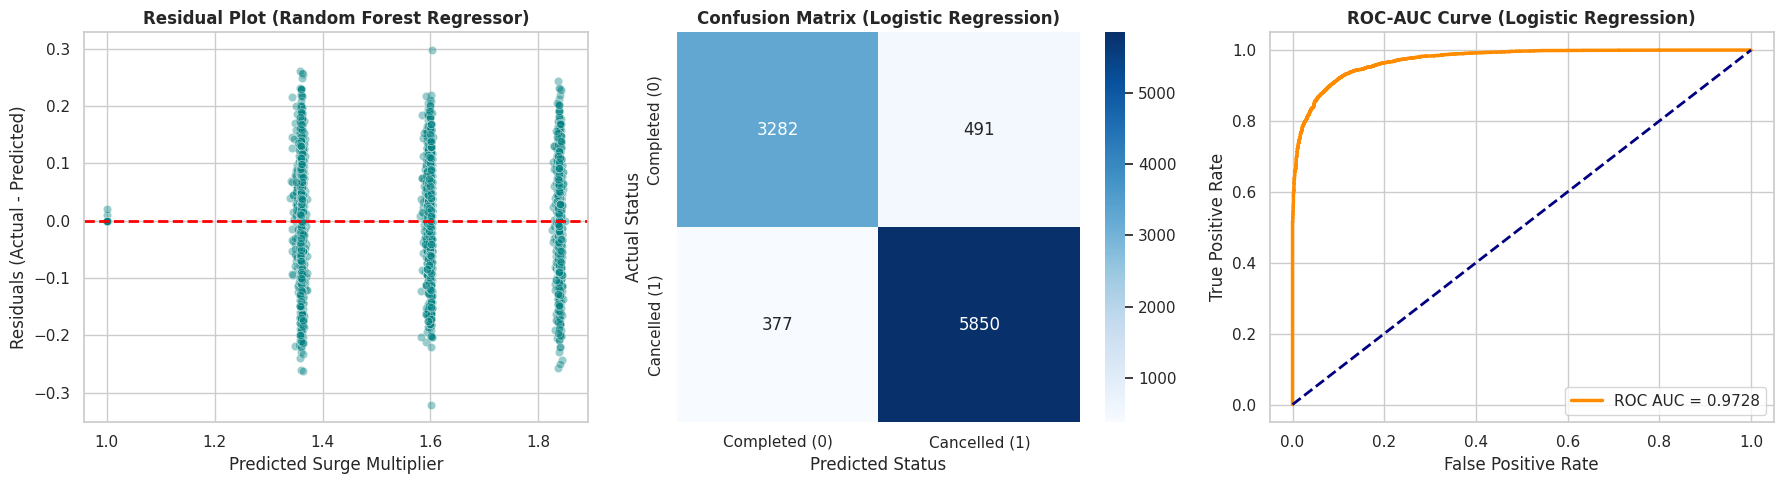

In [8]:
# ==============================================================================
# STEP 7: CROSS-VALIDATION & MODEL EVALUATION PLOTS
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix, roc_curve, auc

# 1. 5-Fold Cross-Validation on Best Classification Model
X_all_scaled = scaler_ml.transform(X)
cv_scores = cross_val_score(best_clf_model, X_all_scaled, y_clf, cv=5, scoring='accuracy', n_jobs=-1)
print(f"5-Fold Cross-Validation Accuracies: {np.round(cv_scores * 100, 2)}")
print(f"Mean Cross-Validation Accuracy     : {cv_scores.mean() * 100:.2f}%\n")

# 2. Generate 3 Evaluation Plots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Regression Residual Plot (Random Forest Regressor)
reg_final_preds = best_reg_model.predict(X_test)
residuals = y_reg_test - reg_final_preds
sns.scatterplot(x=reg_final_preds, y=residuals, color='teal', alpha=0.4, ax=axes[0])
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0].set_title(f'Residual Plot ({best_reg_name})', fontweight='bold')
axes[0].set_xlabel('Predicted Surge Multiplier')
axes[0].set_ylabel('Residuals (Actual - Predicted)')

# Plot 2: Confusion Matrix (Logistic Regression)
cm = confusion_matrix(y_clf_test, best_clf_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Completed (0)', 'Cancelled (1)'],
            yticklabels=['Completed (0)', 'Cancelled (1)'], ax=axes[1])
axes[1].set_title(f'Confusion Matrix ({best_clf_name})', fontweight='bold')
axes[1].set_xlabel('Predicted Status')
axes[1].set_ylabel('Actual Status')

# Plot 3: ROC-AUC Curve (Logistic Regression)
clf_probs = best_clf_model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_clf_test, clf_probs)
roc_auc = auc(fpr, tpr)
axes[2].plot(fpr, tpr, color='darkorange', lw=2.5, label=f'ROC AUC = {roc_auc:.4f}')
axes[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[2].set_title(f'ROC-AUC Curve ({best_clf_name})', fontweight='bold')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()

**Step 8:  (Save ML Models & Scaler)**

In [9]:
# ==============================================================================
# STEP 8: SAVE BEST ML MODELS & SCALER
# ==============================================================================
import joblib

joblib.dump(best_reg_model, 'surge_rf_model.pkl')
joblib.dump(best_clf_model, 'cancel_log_model.pkl')
joblib.dump(scaler_ml, 'ml_feature_scaler.pkl')
joblib.dump(X.columns.tolist(), 'rideflow_features.pkl')

print("Step 8 Completed: Saved 'surge_rf_model.pkl', 'cancel_log_model.pkl', 'ml_feature_scaler.pkl', and 'rideflow_features.pkl'")

Step 8 Completed: Saved 'surge_rf_model.pkl', 'cancel_log_model.pkl', 'ml_feature_scaler.pkl', and 'rideflow_features.pkl'


**Step 9 (Deep Learning ETA Prediction using LSTM)**

In [10]:
# ==============================================================================
# STEP 9: DEEP LEARNING ETA PREDICTION (LSTM) & SAVE MODEL
# ==============================================================================
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

# Select features for sequential ETA prediction
dl_cols = ['Distance_km', 'Demand_Score', 'Supply_Score', 'Is_Raining', 'Hour_of_Day']
dl_scaler = StandardScaler()
X_dl_scaled = dl_scaler.fit_transform(df[dl_cols])

# Reshape to 3D tensor [samples, time_steps, features] using len()
X_lstm = np.reshape(X_dl_scaled, (len(X_dl_scaled), 1, len(dl_cols)))
y_eta = df['ETA_minutes']

X_l_train, X_l_test, y_l_train, y_l_test = train_test_split(X_lstm, y_eta, test_size=0.20, random_state=42)

# Build LSTM Architecture
lstm_model = Sequential([
    LSTM(32, input_shape=(1, len(dl_cols))),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
lstm_model.fit(X_l_train, y_l_train, validation_data=(X_l_test, y_l_test), epochs=8, batch_size=128, verbose=1)

# Evaluate LSTM
lstm_preds = lstm_model.predict(X_l_test, verbose=0).flatten()
print(f"\nLSTM Test Mean Absolute Error (MAE): {mean_absolute_error(y_l_test, lstm_preds):.2f} minutes")

# Save Deep Learning model and scaler
lstm_model.save('eta_lstm_model.h5')
joblib.dump(dl_scaler, 'eta_lstm_scaler.pkl')
print("Step 9 Completed: Saved 'eta_lstm_model.h5' and 'eta_lstm_scaler.pkl'")

Epoch 1/8


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 318.6653 - mae: 14.9003 - val_loss: 14.7204 - val_mae: 3.0346
Epoch 2/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 12.5642 - mae: 2.6460 - val_loss: 5.6802 - val_mae: 1.5206
Epoch 3/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 9.9643 - mae: 2.2525 - val_loss: 4.6195 - val_mae: 1.2522
Epoch 4/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 8.8967 - mae: 2.0629 - val_loss: 4.2214 - val_mae: 1.1293
Epoch 5/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 8.3717 - mae: 1.9646 - val_loss: 4.0856 - val_mae: 1.0889
Epoch 6/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 7.9129 - mae: 1.8806 - val_loss: 3.9892 - val_mae: 1.0608
Epoch 7/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7.6690 - mae: 1.8382 - val_loss: 3.9861 - val_mae: 1.0621
Epoch 8/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7.4231 - mae: 1.7832 - val_loss: 3.9283 - val_mae: 1.0286



LSTM Test Mean Absolute Error (MAE): 1.03 minutes
Step 9 Completed: Saved 'eta_lstm_model.h5' and 'eta_lstm_scaler.pkl'


**Step 10 ( Streamlit Web App)**

In [11]:
!pip install -q streamlit
!wget https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared-linux-amd64
import subprocess
subprocess.Popen(["./cloudflared-linux-amd64", "tunnel", "--url", "http://localhost:8501"])
!nohup /content/cloudflared-linux-amd64 tunnel --url http://localhost:8501 &

--2026-11-19 13:35:49--  https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
Resolving github.com (github.com)... 172.194.218.192
Connecting to github.com (github.com)|172.194.218.192|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/cloudflare/cloudflared/releases/download/2026.11.1/cloudflared-linux-amd64 [following]
--2026-11-19 13:35:49--  https://github.com/cloudflare/cloudflared/releases/download/2026.11.1/cloudflared-linux-amd64
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/106867604/aed2095c-7fa9-4456-a216-57a8025c661f?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-11-19T14%3A21%3A11Z&rscd=attachment%3B+filename%3Dcloudflared-linux-amd64&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026

In [12]:
!pip install streamlit-option-menu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.3/829.3 kB 5.1 MB/s  0:00:00


In [13]:
%%writefile rideflow_app.py
# ==============================================================================
# STEP 10: STREAMLIT WEB APPLICATION (FINAL DEPLOYMENT)
# ==============================================================================
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import tensorflow as tf
from datetime import datetime

st.set_page_config(page_title="Coimbatore RideFlow AI", page_icon="🛺", layout="wide")

@st.cache_resource
def load_models():
    surge_model = joblib.load('surge_rf_model.pkl')
    cancel_model = joblib.load('cancel_log_model.pkl')
    ml_scaler = joblib.load('ml_feature_scaler.pkl')
    feature_cols = joblib.load('rideflow_features.pkl')
    eta_model = tf.keras.models.load_model('eta_lstm_model.h5', compile=False)
    eta_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    dl_scaler = joblib.load('eta_lstm_scaler.pkl')
    return surge_model, cancel_model, ml_scaler, feature_cols, eta_model, dl_scaler

try:
    reg_model, clf_model, ml_scaler, all_columns, lstm_model, dl_scaler = load_models()
    model_status = "🟢 ALL MODELS LOADED SUCCESSFULLY"
except Exception as e:
    model_status = f"🔴 ERROR LOADING MODELS: {str(e)}"
    reg_model, clf_model, ml_scaler, all_columns, lstm_model, dl_scaler = None, None, None, None, None, None

# Sidebar Controls
st.sidebar.markdown(f"### **System Status:**\n`{model_status}`")
st.sidebar.header("🛺 Dispatch Control Panel")

zones = ['Saravanampatti', 'Gandhipuram', 'Peelamedu', 'RS Puram', 'Ukkadam']
pickup = st.sidebar.selectbox("Select Pickup Zone", zones, index=0)
drop = st.sidebar.selectbox("Select Drop Zone", zones, index=1)

current_hour = st.sidebar.slider("Hour of Day (24-Hr Format)", 0, 23, datetime.now().hour)
distance = st.sidebar.slider("Estimated Route Distance (km)", 1.0, 25.0, 6.0, step=0.5)
demand = st.sidebar.slider("Local Demand Score (1-10)", 1, 10, 7)
supply = st.sidebar.slider("Available Auto Drivers (1-10)", 1, 10, 4)

rain_input = st.sidebar.selectbox("Weather Condition", ["Clear Sky", "Heavy Rain Storm"])
fest_input = st.sidebar.selectbox("Day Classification", ["Normal Day", "Festival Day"])
extra_input = st.sidebar.selectbox("Driver Tariff Dispute Status", ["No Dispute", "Driver Asks Extra Cash"])

is_raining = 1.0 if rain_input == "Heavy Rain Storm" else 0.0
is_festival = 1.0 if fest_input == "Festival Day" else 0.0
asks_extra = 1.0 if extra_input == "Driver Asks Extra Cash" else 0.0
current_day = datetime.now().strftime('%A')

# Main Dashboard
st.title("🛺 Coimbatore RideFlow AI Operations Room")
st.markdown("### **End-to-End Intelligent Ride Optimization System (ML + DL)**")
st.divider()

if "🟢" in model_status:
    col1, col2, col3, col4 = st.columns(4)

    # Prepare Feature Dictionary
    input_data = {col: 0.0 for col in all_columns}
    input_data['Hour_of_Day'] = float(current_hour)
    input_data['Distance_km'] = float(distance)
    input_data['Demand_Score'] = float(demand)
    input_data['Supply_Score'] = float(supply)
    input_data['Demand_Supply_Gap'] = float(demand - supply)
    input_data['Is_Raining'] = is_raining
    input_data['Is_Festival'] = is_festival
    input_data['Driver_Asks_Extra'] = asks_extra

    if f"Pickup_Zone_{pickup}" in input_data: input_data[f"Pickup_Zone_{pickup}"] = 1.0
    if f"Drop_Zone_{drop}" in input_data: input_data[f"Drop_Zone_{drop}"] = 1.0
    if f"Day_of_Week_{current_day}" in input_data: input_data[f"Day_of_Week_{current_day}"] = 1.0

    X_query = pd.DataFrame([input_data])[all_columns]

    # Step A: Deep Learning LSTM ETA Prediction
    dl_cols = ['Distance_km', 'Demand_Score', 'Supply_Score', 'Is_Raining', 'Hour_of_Day']
    dl_features = pd.DataFrame([[distance, demand, supply, is_raining, current_hour]], columns=dl_cols)
    dl_features_scaled = dl_scaler.transform(dl_features)
    X_lstm_query = np.reshape(dl_features_scaled, (1, 1, 5))

    predicted_eta = max(1.0, round(float(lstm_model.predict(X_lstm_query, verbose=0).item()), 1))
    X_query['ETA_minutes'] = predicted_eta

    # Step B: Machine Learning Surge & Cancellation Prediction
    predicted_surge = max(1.0, min(2.2, round(float(reg_model.predict(X_query).item()), 2)))

    if distance <= 2:
        base_fare = 40.0
    elif distance <= 10:
        base_fare = 40.0 + (distance - 2) * 15.0
    else:
        base_fare = 40.0 + (8 * 15.0) + (distance - 10) * 14.0

    if (current_hour >= 22) or (current_hour < 6): base_fare *= 1.5
    if is_raining == 1.0: base_fare += 50.0
    final_computed_fare = round(base_fare * predicted_surge, 2)

    # Scale X_query for Logistic Regression Cancellation Model
    X_query_scaled = ml_scaler.transform(X_query)
    cancellation_probability = float(clf_model.predict_proba(X_query_scaled)[:, 1].item())

    # Display Metrics
    with col1:
        st.metric(label="⏱️ LSTM Predicted ETA", value=f"{predicted_eta} Mins")
    with col2:
        st.metric(label="📈 Dynamic Surge Multiplier", value=f"{predicted_surge}x")
    with col3:
        st.metric(label="💰 Final Computed Fare", value=f"₹{final_computed_fare}")
    with col4:
        st.metric(label="🚨 Cancellation Risk", value=f"{round(cancellation_probability * 100, 1)}%")

    st.divider()
    st.subheader("🤖 Fleet Predictive Analytics Dispatch Summary")
    st.progress(min(1.0, max(0.0, cancellation_probability)))
    st.markdown(f"**Route Vector:** `{pickup}` ➡️ `{drop}` | **Time:** `{current_day}, {current_hour}:00 hrs`")

    if cancellation_probability > 0.60:
        st.error("🚨 HIGH DISPATCH RISK: Elevated risk of driver cancellation due to tariff dispute, high ETA, or peak demand.")
    else:
        st.success("✨ OPTIMAL ROUTE: Low cancellation probability. High ride completion rate expected.")
else:
    st.error("Please ensure all model files (.pkl, .h5) are present in the repository root.")

Writing rideflow_app.py


In [35]:
!streamlit run /content/rideflow_app.py &>/content/logs.txt &

In [36]:
!grep -o 'https://.*\.trycloudflare.com' nohup.out | head -n 1 | xargs -I {} echo "Your tunnel url {}"

Your tunnel url https://advert-documents-russell-acm.trycloudflare.com
